In [ ]:

from google.colab import files

uploaded = files.upload()


Saving clinical-semantic-heterogeneity-starter.zip to clinical-semantic-heterogeneity-starter (1).zip


In [ ]:

import zipfile

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as zip_file:
    zip_file.extractall("/content")

print("Project extracted successfully!")


Project extracted successfully!


In [ ]:

%cd /content/clinical-semantic-heterogeneity

!ls


/content/clinical-semantic-heterogeneity
data	 PROGRESS_LOG.md  requirements.txt    results  src
figures  README.md	  RESEARCH_DESIGN.md  scripts  tests


In [ ]:

!python -m pip install -r requirements.txt


  Attempting uninstall: pytest
    Found existing installation: pytest 8.4.2
    Uninstalling pytest-8.4.2:
      Successfully uninstalled pytest-8.4.2


In [ ]:

!python -m pytest tests -q


.........                                                                [100%]
9 passed in 1.39s


In [ ]:

!python scripts/01_inspect_dataset.py --download


DATA AUDIT COMPLETE — no model was trained
Encounters: 101,766 | Patients: 71,518
Readmission categories: {'<30': 11357, '>30': 35545, 'NO': 54864}
Inpatient/emergency values differ in: 36199 rows
Source CSV SHA-256: 0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97
Row count matches UCI 101,766: True
Saved: /content/clinical-semantic-heterogeneity/results/data_audit.json and /content/clinical-semantic-heterogeneity/results/dataset_manifest.json


The dataset contains 101,766 hospital encounters representing 71,518 patients. This means some patients have multiple encounters, which could create data leakage if I randomly split the dataset by rows.

I also examined two clinical utilization features: number_inpatient and number_emergency. Approximately 35.57% of encounters have different values for these two features.

This makes them useful candidates for a controlled mapping experiment because swapping their values would change the information represented for some records.

However, this does not mean model performance will necessarily decrease. I still need to test how much the model depends on these features.


In [ ]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/audit_results",
    "zip",
    root_dir="results"
)

files.download("/content/audit_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
## Phase 2: Experimental Design Validation

In [8]:
from google.colab import files
files.upload()

Saving clinical-semantic-heterogeneity-phase2-prep.zip to clinical-semantic-heterogeneity-phase2-prep.zip


{'clinical-semantic-heterogeneity-phase2-prep.zip': b'PK\x03\x04\n\x00\x00\x00\x00\x00\xe7\x96b]\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00 \x00\x1c\x00clinical-semantic-heterogeneity/UT\t\x00\x03\x92\xdc\xe8j\x92\xdc\xe8jux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\xe9\x03\x00\x00PK\x03\x04\n\x00\x00\x00\x00\x00\x8a\x96b]\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00%\x00\x1c\x00clinical-semantic-heterogeneity/data/UT\t\x00\x03\xe4\xdb\xe8j\xe4\xdb\xe8jux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\xe9\x03\x00\x00PK\x03\x04\x14\x00\x00\x00\x08\x00eVb]=\xa7\'U \x03\x00\x00j\x05\x00\x00.\x00\x1c\x00clinical-semantic-heterogeneity/data/README.mdUT\t\x00\x03\x1ek\xe8j\x1ek\xe8jux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\xe9\x03\x00\x00\x95T\xdbn\xdb8\x10}\xf7W\x0c\xb0\xc0\xd6\x91mYq\xd2\xb4q\x17\x0b$2\x16q7\xad\x17q[\xa0(\x8a\x88&G\xf6`%R\xe0E\x89\xfb\xd4\x7f\xd8?\xdc/\xe9P\xbe @Q\x14}\x12E\xce9sf\xe6\x90\xbf\xc1\xfb|\x0eJx\xe1\xd0\x83\xd0\n\x1akZ\xd4BK\xec\xf5\x92di\x82\x95\x98$S\xf84#\xb1B\x8f\x0eN

In [9]:

!unzip -oq clinical-semantic-heterogeneity-phase2-prep.zip -d /content

%cd /content/clinical-semantic-heterogeneity


/content/clinical-semantic-heterogeneity


In [10]:

!python -m pip install -q -r requirements.txt

!python -m pytest tests -q

!python scripts/01_inspect_dataset.py --download

!python scripts/02_prepare_design.py


................                                                         [100%]
16 passed in 2.03s
DATA AUDIT COMPLETE — no model was trained
Encounters: 101,766 | Patients: 71,518
Readmission categories: {'<30': 11357, '>30': 35545, 'NO': 54864}
Inpatient/emergency values differ in: 36199 rows
Source CSV SHA-256: 0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97
Row count matches UCI 101,766: True
Saved: /content/clinical-semantic-heterogeneity/results/data_audit.json and /content/clinical-semantic-heterogeneity/results/dataset_manifest.json
DESIGN AUDIT COMPLETE — no models trained
Patient overlap across clients: 0
Patient overlap across train/validation/test: 0
Changed training rows in simulated client 0: 8482
Oracle restoration exact: True
Saved: /content/clinical-semantic-heterogeneity/results/design_audit.json


In [11]:

from google.colab import files

files.download(
    "/content/clinical-semantic-heterogeneity/results/design_audit.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Phase 2B: Reviewing the data splits

Before training a prediction model, I want to check how
patient encounters are distributed across the simulated
clients and the training, validation, and test sets.

I will also compare the 30-day readmission rates to
understand whether the groups have similar outcomes.


In [12]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: /content/clinical-semantic-heterogeneity
Files: ['README.md', '.gitignore', 'PHASE1_REVIEW.md', 'results', 'PROGRESS_LOG.md', 'data', 'RESEARCH_DESIGN.md', '.pytest_cache', 'figures', 'scripts', 'src', 'requirements.txt', 'tests']


In [13]:
from pathlib import Path

files = list(Path("/content").rglob("design_audit.json"))

print("Found:", files)

Found: [PosixPath('/content/clinical-semantic-heterogeneity/results/design_audit.json')]


In [14]:

import json
import pandas as pd

file_path = "/content/clinical-semantic-heterogeneity/results/design_audit.json"

with open(file_path) as file:
    audit = json.load(file)

splits = pd.DataFrame(audit["client_split_summary"])

splits["readmission_rate_%"] = (
    splits["positive_fraction"] * 100
).round(2)

display(splits[[
    "client",
    "split",
    "patients",
    "encounters",
    "positive_encounters",
    "readmission_rate_%"
]])


,client,split,patients,encounters,positive_encounters,readmission_rate_%
0,0,train,16688,23820,2645,11.10
1,0,validation,3576,5096,571,11.20
2,0,test,3576,5129,568,11.07
3,1,train,16687,23712,2640,11.13
4,1,validation,3575,5103,600,11.76
5,1,test,3577,5118,595,11.63
6,2,train,16687,23665,2620,11.07
7,2,validation,3575,5051,578,11.44
8,2,test,3577,5072,540,10.65



### Phase 2B: Preparing Features and Labels

I will prepare the eight numeric clinical features selected
during Phase 1.

The prediction target is whether an encounter is followed
by readmission within 30 days.

I will reuse the patient-group assignments from Phase 2A
to keep the experiment consistent.


In [15]:

import pandas as pd

from src.data_contract import NUMERIC_FEATURES
from src.experimental_design import make_patient_partitions

data = pd.read_csv("data/raw/diabetic_data.csv", na_values=["?"])

# Recreate the same patient assignments
groups = make_patient_partitions(data, seed=2026)

# Prepare the inputs and prediction target
features = list(NUMERIC_FEATURES)
X = data[features].copy()
y = (data["readmitted"] == "<30").astype(int)

print("Features used:", features)
print("\nNumber of encounters:", len(X))
print("Missing feature values:", X.isna().sum().sum())
print("Readmitted within 30 days:", y.sum())
print("Other outcomes:", (y == 0).sum())


/tmp/ipykernel_1523/3246071639.py:6: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("data/raw/diabetic_data.csv", na_values=["?"])


Features used: ['number_inpatient', 'number_emergency', 'time_in_hospital', 'num_medications', 'num_lab_procedures', 'num_procedures', 'number_diagnoses', 'number_outpatient']

Number of encounters: 101766
Missing feature values: 0
Readmitted within 30 days: 11357
Other outcomes: 90409



### Preparing Training, Validation, and Test Data

I will use the patient-based partitions created in Phase 2A.

The training data will be used to build the prediction model.
The validation data will help evaluate its performance
during development, while the test data will be reserved
for the final comparison.

This helps avoid patient overlap between the datasets.


In [16]:

# Use the same partitions created earlier

train_rows = groups["split"] == "train"
val_rows = groups["split"] == "validation"
test_rows = groups["split"] == "test"

X_train = X.loc[train_rows]
y_train = y.loc[train_rows]

X_val = X.loc[val_rows]
y_val = y.loc[val_rows]

X_test = X.loc[test_rows]
y_test = y.loc[test_rows]

print("Training encounters:", len(X_train))
print("Validation encounters:", len(X_val))
print("Test encounters:", len(X_test))

print("\nTraining readmission rate:",
      round(y_train.mean() * 100, 2), "%")

print("Validation readmission rate:",
      round(y_val.mean() * 100, 2), "%")


Training encounters: 71197
Validation encounters: 15250
Test encounters: 15319

Training readmission rate: 11.1 %
Validation readmission rate: 11.47 %



### Training the Baseline Model (E0)

I will train a logistic regression model using the
original clinical features without any mapping errors.

The model will learn patterns associated with 30-day
hospital readmission.

I will standardize the features because they have
different numerical ranges. The scaling will be
learned from the training data only.


In [17]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build the baseline model
model_e0 = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=2026)
)

# Train using correctly mapped data
model_e0.fit(X_train, y_train)

print("E0 baseline model trained successfully.")
print("Training encounters:", len(X_train))
print("Features:", X_train.shape[1])


E0 baseline model trained successfully.
Training encounters: 71197
Features: 8



### Evaluating the Baseline Model (E0)

After training the baseline model, I will evaluate its
performance using the validation dataset.

I will calculate AUROC, AUPRC, and Brier score to
understand how well the model distinguishes readmission
cases and estimates readmission probabilities.

The test dataset will remain unused until the final
experiment.


In [18]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# Predict readmission probabilities
prob_e0 = model_e0.predict_proba(X_val)[:, 1]

# Calculate evaluation metrics
auc_e0 = roc_auc_score(y_val, prob_e0)
auprc_e0 = average_precision_score(y_val, prob_e0)
brier_e0 = brier_score_loss(y_val, prob_e0)

print("E0 Baseline - Validation Results")
print("AUROC:", round(auc_e0, 4))
print("AUPRC:", round(auprc_e0, 4))
print("Brier Score:", round(brier_e0, 4))
print("Readmission Rate:", round(y_val.mean(), 4))


E0 Baseline - Validation Results
AUROC: 0.6294
AUPRC: 0.2031
Brier Score: 0.0984
Readmission Rate: 0.1147



### E1: Introducing a Clinical Mapping Error

In this experiment, I will introduce a controlled
mapping error into Client 0's training data.

The inpatient and emergency visit counts will be
exchanged, while the other features and readmission
labels remain unchanged.

I will compare this condition against E0 to study
whether incorrect feature mappings influence
model predictions.


In [19]:

from src.experimental_design import swapped_utilization_fields

# Keep the original training data unchanged
X_train_e1 = X_train.copy()

# Find Client 0's training records
client0 = groups.loc[X_train.index, "client"] == 0

# Introduce the mapping error
X_train_e1.loc[client0] = swapped_utilization_fields(
    X_train_e1.loc[client0]
)

# Count the records with different feature values
changed = (
    X_train_e1["number_inpatient"] != X_train["number_inpatient"]
).sum()

print("Client 0 training encounters:", client0.sum())
print("Records changed:", changed)
print("Other client records unchanged:",
      X_train_e1.loc[~client0].equals(X_train.loc[~client0]))


Client 0 training encounters: 23820
Records changed: 8482
Other client records unchanged: True



### Training the Model with Incorrect Feature Mapping (E1)

I will train another logistic regression model using the
modified training data.

I will keep the model settings the same as E0 so that
the mapping error is the main difference between the
two experiments.

The validation dataset will remain unchanged.


In [20]:

from sklearn.base import clone

# Create a fresh model with the same settings as E0
model_e1 = clone(model_e0)

# Train using the modified data
model_e1.fit(X_train_e1, y_train)

print("E1 model trained successfully.")
print("Training encounters:", len(X_train_e1))
print("Features:", X_train_e1.shape[1])
print("Modified records:", changed)


E1 model trained successfully.
Training encounters: 71197
Features: 8
Modified records: 8482



### Comparing E0 and E1

I will evaluate E1 using the same validation records
used for E0.

I will compare AUROC, AUPRC, and Brier score to examine
whether the mapping error changes prediction performance.

The results will help me understand the effect of the
controlled feature-mapping error.


In [21]:

# Predict using the unchanged validation data
prob_e1 = model_e1.predict_proba(X_val)[:, 1]

auc_e1 = roc_auc_score(y_val, prob_e1)
auprc_e1 = average_precision_score(y_val, prob_e1)
brier_e1 = brier_score_loss(y_val, prob_e1)

results = pd.DataFrame({
    "Metric": ["AUROC", "AUPRC", "Brier Score"],
    "E0": [auc_e0, auprc_e0, brier_e0],
    "E1": [auc_e1, auprc_e1, brier_e1]
})

results["Difference (E1 - E0)"] = results["E1"] - results["E0"]

display(results.round(4))


,Metric,E0,E1,Difference (E1 - E0)
0,AUROC,0.6294,0.6279,-0.0015
1,AUPRC,0.2031,0.1994,-0.0037
2,Brier Score,0.0984,0.0986,0.0002



### E0 and E1: Initial Observation

The model trained with incorrect feature mapping (E1)
showed slightly lower AUROC and AUPRC than the baseline
model (E0). Its Brier score also increased slightly.

This suggests that the mapping error affected model
performance, although the differences were small.

These are preliminary results from one experimental run.
Further testing is needed to understand whether the
observed differences are consistent.



### E2: Restoring the Correct Feature Mapping

I will correct the mapping error introduced in E1
by restoring the original inpatient and emergency
visit counts.

I will verify whether the corrected training data
matches the original E0 training data.


In [22]:

# Creating a copy of the modified training data
X_train_e2 = X_train_e1.copy()

# Restoring Client 0's original feature values
X_train_e2.loc[client0] = swapped_utilization_fields(
    X_train_e2.loc[client0]
)

# Comparing the restored data with E0
restored = X_train_e2.equals(X_train)

print("E2 Mapping Restoration")
print("Original data restored:", restored)
print("Training encounters:", len(X_train_e2))
print("Features:", X_train_e2.shape[1])


E2 Mapping Restoration
Original data restored: True
Training encounters: 71197
Features: 8



### E2: Evaluating the Restored Mapping

The original feature values were successfully restored.

I will now train the model again using the corrected
data and compare its validation performance with E0.

Since the training data and model settings are the same,
I expect the results to match the baseline.


In [24]:

from sklearn.base import clone

# Train a fresh model using the restored data
model_e2 = clone(model_e0)
model_e2.fit(X_train_e2, y_train)

# Evaluate on the same validation records
prob_e2 = model_e2.predict_proba(X_val)[:, 1]

auc_e2 = roc_auc_score(y_val, prob_e2)
auprc_e2 = average_precision_score(y_val, prob_e2)
brier_e2 = brier_score_loss(y_val, prob_e2)

comparison = pd.DataFrame({
    "Metric": ["AUROC", "AUPRC", "Brier Score"],
    "E0": [auc_e0, auprc_e0, brier_e0],
    "E1": [auc_e1, auprc_e1, brier_e1],
    "E2": [auc_e2, auprc_e2, brier_e2]
})

display(comparison.round(4))


,Metric,E0,E1,E2
0,AUROC,0.6294,0.6279,0.6294
1,AUPRC,0.2031,0.1994,0.2031
2,Brier Score,0.0984,0.0986,0.0984


Three observations matter:
- E0: Our model demonstrated modest predictive ability using the original features.
- E1: Introducing incorrect feature mappings slightly reduced AUROC and AUPRC and increased the Brier score.
- E2: Restoring the correct feature mappings reproduced the E0 results to four decimal places.
This is consistent with our hypothesis that incorrect clinical feature mappings can affect prediction reliability.

However, the differences are small. We cannot yet conclude that they are statistically meaningful or generalizable to other datasets.


### Comparing Individual Prediction Differences

Although E0 and E1 have similar overall performance,
I want to examine whether their predicted readmission
probabilities differ for individual encounters.

I will compare predictions from both models using
the same validation records.

I will also check whether E2 reproduces the original
E0 predictions after restoring the feature mapping.


In [25]:

import numpy as np

# Comparing predictions for the same validation records
difference = np.abs(prob_e0 - prob_e1)

print("E0 vs E1 Prediction Differences")
print("Mean difference:", round(difference.mean(), 4))
print("Median difference:", round(np.median(difference), 4))
print("Largest difference:", round(difference.max(), 4))

# Counting changes of at least 1 percentage point
large_changes = (difference >= 0.01).sum()

print("\nEncounters with a change of at least 1 percentage point:",
      large_changes)

print("Percentage of validation encounters:",
      round(large_changes / len(difference) * 100, 2), "%")

# Checking whether restored predictions match E0
restoration_match = np.allclose(
    prob_e0, prob_e2, rtol=0, atol=1e-10
)

print("\nE2 predictions match E0:", restoration_match)


E0 vs E1 Prediction Differences
Mean difference: 0.0087
Median difference: 0.0035
Largest difference: 0.6436

Encounters with a change of at least 1 percentage point: 2989
Percentage of validation encounters: 19.6 %

E2 predictions match E0: True



### Examining the Largest Prediction Differences

I observed that some validation encounters had much
larger prediction differences than others.

I will examine the five encounters with the largest
differences to understand how the two models behaved.

This may help identify patterns that are not visible
in the overall evaluation metrics.


In [26]:

# Comparing predictions for each validation encounter
prediction_review = pd.DataFrame({
    "E0_probability": prob_e0,
    "E1_probability": prob_e1,
    "actual_readmission": y_val.to_numpy()
}, index=X_val.index)

prediction_review["difference"] = (
    prediction_review["E0_probability"]
    - prediction_review["E1_probability"]
).abs()

# Finding the five largest differences
top_five = prediction_review.nlargest(5, "difference")

display(top_five.round(4))


,E0_probability,E1_probability,actual_readmission,difference
9805,0.2104,0.8540,1,0.6436
9845,0.2997,0.8891,0,0.5894
11600,0.4438,0.9566,0,0.5129
27520,0.2591,0.6518,0,0.3927
68344,0.3621,0.6789,0,0.3168



### Examining Clinical Features for the Largest Changes

The five encounters with the largest prediction
differences all received higher probabilities under E1.

I want to examine their inpatient and emergency visit
counts to see whether unusual utilization values
could help explain these differences.


In [27]:

# Review the two features involved in our mapping error
case_review = X_val.loc[
    top_five.index,
    ["number_inpatient", "number_emergency"]
].copy()

case_review["actual_readmission"] = y_val.loc[top_five.index]

case_review["E0_probability"] = top_five["E0_probability"]
case_review["E1_probability"] = top_five["E1_probability"]
case_review["difference"] = top_five["difference"]

display(case_review.round(4))


,number_inpatient,number_emergency,actual_readmission,E0_probability,E1_probability,difference
9805,3,22,1,0.2104,0.8540,0.6436
9845,5,22,0,0.2997,0.8891,0.5894
11600,6,25,0,0.4438,0.9566,0.5129
27520,4,13,0,0.2591,0.6518,0.3927
68344,5,11,0,0.3621,0.6789,0.3168



### Checking the Distribution of Utilization Features

The five encounters with the largest prediction changes
had higher emergency visit counts than inpatient counts.

I will compare these values with the overall validation
dataset to see whether they are unusually high.

This will help me investigate a possible explanation
for the large prediction differences.


In [28]:

# Examining the distribution of the two utilization features
columns = ["number_inpatient", "number_emergency"]

summary = X_val[columns].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
)

display(summary.round(2))


,number_inpatient,number_emergency
count,15250.00,15250.00
mean,0.65,0.20
std,1.34,0.78
min,0.00,0.00
50%,0.00,0.00
90%,2.00,1.00
95%,3.00,1.00
99%,6.00,3.00
max,16.00,25.00


Important Note To Remember: Remember what our experiment did:

E0: Train logistic regression with the correct inpatient and emergency feature mappings.

E1: Swap these features for Client 0's training records, then retrain the same model.

Our findings suggest a possible explanation:

When the model learns from incorrectly mapped utilization features, it may learn different relationships between emergency visits, inpatient visits, and readmission.

Those differences could be particularly noticeable for encounters with extreme feature values.

But we must distinguish two statements:
- Observed: The five largest prediction differences occurred in encounters with unusually high emergency-visit counts.
- Not yet established: High emergency-visit counts caused those prediction differences.


### Prediction Differences by Emergency Visit Count

The five encounters with the largest prediction changes
had unusually high emergency visit counts.

I will now examine the entire validation dataset to
see whether prediction differences are also larger
among encounters with higher emergency utilization.

This will help me understand whether the pattern
extends beyond the five selected cases.


In [29]:

# Comparing prediction changes across emergency visit groups
review = X_val[["number_emergency"]].copy()

review["prediction_change"] = abs(prob_e0 - prob_e1)

review["emergency_group"] = pd.cut(
    review["number_emergency"],
    bins=[-1, 0, 3, float("inf")],
    labels=["0 visits", "1-3 visits", "4+ visits"]
)

summary = review.groupby(
    "emergency_group", observed=True
)["prediction_change"].agg(["count", "mean", "median", "max"])

# Now Converting probability differences to percentage points
for column in ["mean", "median", "max"]:
    summary[column] = (summary[column] * 100).round(2)

display(summary)


,count,mean,median,max
emergency_group,,,,
0 visits,13497,0.61,0.32,21.75
1-3 visits,1610,2.12,1.62,19.19
4+ visits,143,11.26,8.51,64.36


### My question for Research :  Are clinical encounters with unusually high utilization values more sensitive to inconsistencies in the mapping of clinical features?


### Examining the Model Coefficients

I will compare the coefficients for inpatient and
emergency visits in E0 and E1.

This will help me understand whether the mapping error
changed the relationships learned by logistic regression.

The coefficients describe associations in the model,
not causal relationships.


In [30]:

# Compare model coefficients in original feature units
def get_coefficients(model):
    scaler = model.named_steps["standardscaler"]
    regression = model.named_steps["logisticregression"]

    coefficients = regression.coef_[0] / scaler.scale_

    return pd.Series(coefficients, index=X_train.columns)


coef_e0 = get_coefficients(model_e0)
coef_e1 = get_coefficients(model_e1)

features_to_check = ["number_inpatient", "number_emergency"]

comparison = pd.DataFrame({
    "E0": coef_e0[features_to_check],
    "E1": coef_e1[features_to_check]
})

comparison["Difference"] = comparison["E1"] - comparison["E0"]

display(comparison.round(4))


,E0,E1,Difference
number_inpatient,0.2689,0.1916,-0.0773
number_emergency,0.0205,0.1704,0.1500



### Phase 2B: Preliminary Findings

The controlled mapping error produced small changes in
overall model performance but larger changes in some
individual predictions.

Prediction differences were associated with emergency
utilization. Encounters with four or more emergency
visits had an average absolute prediction difference
of 11.26 percentage points, compared with 0.61
percentage points for encounters with no emergency visits.

This suggests that the effects of incorrect feature
mapping may not be uniform across clinical records.

These findings are preliminary and require additional
robustness testing before stronger conclusions can
be drawn.



### Phase 2B: Conclusion

The E0, E1, and E2 experiments were completed successfully.

Introducing an incorrect mapping between inpatient and
emergency visit counts slightly reduced the model's
overall validation performance.

However, some individual predictions changed substantially,
especially for encounters with high emergency utilization.

The emergency-visit coefficient increased from 0.0205
in E0 to 0.1704 in E1. This helps explain the higher
predicted probabilities observed for some encounters.

Restoring the correct mapping reproduced the E0 results.

These findings are preliminary because the experiment
used one patient partition and one model configuration.
Further experiments are needed to check their stability.


In [32]:

from pathlib import Path

# Saving our first experimental comparison
output = Path("results")
output.mkdir(exist_ok=True)

comparison.to_csv(output / "phase2b_coefficients.csv")
results.to_csv(output / "phase2b_model_comparison.csv", index=False)

print("Phase 2B results saved!")


Phase 2B results saved!



### Phase 3: Testing Different Client Assignments

In Phase 2B, I introduced the mapping error into one
simulated client's training data.

I will now repeat the client assignment using five
different random seeds.

The original training, validation, and test sets will
remain unchanged. Only the assignment of training
patients to simulated clients will change.

This will help me examine whether the results depend
on which patients receive the mapping error.


In [34]:

import numpy as np
import pandas as pd

# Using only the patients in our original training set
train_patients = groups.loc[X_train.index, "patient_nbr"]
patient_ids = np.sort(train_patients.unique())

seeds = [2027, 2028, 2029, 2030, 2031]

client_masks = {}
seed_summary = []

for seed in seeds:
    shuffled = patient_ids.copy()
    np.random.default_rng(seed).shuffle(shuffled)

    # Now I Divide training patients into three simulated clients
    clients = np.array_split(shuffled, 3)

    # Then Client 0 will receive the mapping error
    client0 = train_patients.isin(clients[0])
    client_masks[seed] = client0

    changed = (
        X_train.loc[client0, "number_inpatient"]
        != X_train.loc[client0, "number_emergency"]
    ).sum()

    seed_summary.append({
        "Seed": seed,
        "Client 0 patients": len(clients[0]),
        "Client 0 encounters": int(client0.sum()),
        "Rows that would change": int(changed)
    })

display(pd.DataFrame(seed_summary))


,Seed,Client 0 patients,Client 0 encounters,Rows that would change
0,2027,16688,23606,8303
1,2028,16688,23689,8364
2,2029,16688,23772,8498
3,2030,16688,23648,8383
4,2031,16688,23706,8401



### Phase 3: Repeating the Mapping Error Experiment

I will train five new models using different client
assignments.

Each experiment will introduce the same mapping error
into Client 0's training records.

I will keep the model settings and validation data
unchanged, then compare the results against E0.

This will help me determine whether the observed
effects depend on which training patients receive
the mapping error.


In [35]:

from sklearn.base import clone

phase3_results = []

for seed in seeds:

    # Starting with the original training data
    modified_data = X_train.copy()

    # Applying the swap to Client 0
    affected_rows = client_masks[seed]

    modified_data.loc[affected_rows] = swapped_utilization_fields(
        modified_data.loc[affected_rows]
    )

    # Training a new model
    model = clone(model_e0)
    model.fit(modified_data, y_train)

    # Evaluating on the original validation data
    probabilities = model.predict_proba(X_val)[:, 1]

    phase3_results.append({
        "Seed": seed,
        "AUROC": roc_auc_score(y_val, probabilities),
        "AUPRC": average_precision_score(y_val, probabilities),
        "Brier": brier_score_loss(y_val, probabilities)
    })

phase3_results = pd.DataFrame(phase3_results)

display(phase3_results.round(4))


,Seed,AUROC,AUPRC,Brier
0,2027,0.6283,0.1999,0.0985
1,2028,0.6282,0.1998,0.0985
2,2029,0.6292,0.2015,0.0984
3,2030,0.6293,0.2015,0.0984
4,2031,0.6291,0.2012,0.0984


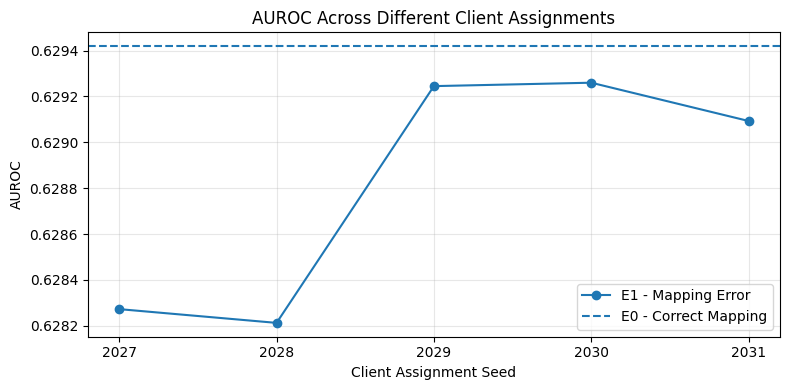

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    phase3_results["Seed"],
    phase3_results["AUROC"],
    marker="o",
    label="E1 - Mapping Error"
)

plt.axhline(
    y=auc_e0,
    linestyle="--",
    label="E0 - Correct Mapping"
)

plt.xlabel("Client Assignment Seed")
plt.ylabel("AUROC")
plt.title("AUROC Across Different Client Assignments")

plt.xticks(phase3_results["Seed"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()



### Phase 3: Comparing Results Across Repetitions

I repeated the mapping-error experiment using five
different client assignments.

All five experiments showed slightly lower AUROC and
AUPRC than the original baseline.

I will calculate the differences and their variability
to understand how consistent these changes are.


In [37]:

# Comparing each experiment with E0
phase3_comparison = phase3_results.copy()

phase3_comparison["AUROC_change"] = (
    phase3_comparison["AUROC"] - auc_e0
)

phase3_comparison["AUPRC_change"] = (
    phase3_comparison["AUPRC"] - auprc_e0
)

phase3_comparison["Brier_change"] = (
    phase3_comparison["Brier"] - brier_e0
)

# Reviewing the differences for each seed
display(phase3_comparison.round(5))

# Summarizing the average change and variation
change_columns = [
    "AUROC_change",
    "AUPRC_change",
    "Brier_change"
]

print("Average performance change:")
print(phase3_comparison[change_columns].mean().round(5))

print("\nStandard deviation across assignments:")
print(phase3_comparison[change_columns].std().round(5))


,Seed,AUROC,AUPRC,Brier,AUROC_change,AUPRC_change,Brier_change
0,2027,0.62827,0.19990,0.09852,-0.00115,-0.00323,0.00015
1,2028,0.62821,0.19981,0.09852,-0.00121,-0.00332,0.00015
2,2029,0.62924,0.20154,0.09842,-0.00017,-0.00159,0.00005
3,2030,0.62926,0.20149,0.09841,-0.00016,-0.00164,0.00004
4,2031,0.62909,0.20122,0.09843,-0.00033,-0.00191,0.00006


Average performance change:
AUROC_change   -0.00060
AUPRC_change   -0.00234
Brier_change    0.00009
dtype: float64

Standard deviation across assignments:
AUROC_change    0.00053
AUPRC_change    0.00086
Brier_change    0.00005
dtype: float64



### Phase 3: Repeated Experiment Results

I repeated the mapping-error experiment using five
different simulated-client assignments.

All five E1 models showed slightly lower AUROC and
AUPRC than E0, along with slightly higher Brier scores.

The average AUROC change was -0.00060, and the
average AUPRC change was -0.00234.

The results suggest that the direction of the mapping
error's effect was consistent across these assignments,
although the overall performance changes were small.

These experiments used the same training, validation,
and test partitions. Therefore, the results describe
variation across client assignments rather than
general uncertainty across different patient samples.



### Phase 3: Prediction Sensitivity Across Client Assignments

In Phase 2B, I observed larger prediction differences
for encounters with high emergency utilization.

I will now repeat this analysis across five client
assignments to see whether the same pattern appears.

I will compare the average absolute difference between
E0 and E1 predictions for three emergency-visit groups.


In [38]:

import numpy as np
from sklearn.base import clone

sensitivity_results = []

emergency_groups = pd.cut(
    X_val["number_emergency"],
    bins=[-1, 0, 3, np.inf],
    labels=["0 visits", "1-3 visits", "4+ visits"]
)

for seed in seeds:
    modified_data = X_train.copy()
    affected_rows = client_masks[seed]

    modified_data.loc[affected_rows] = swapped_utilization_fields(
        modified_data.loc[affected_rows]
    )

    model = clone(model_e0)
    model.fit(modified_data, y_train)

    predictions = model.predict_proba(X_val)[:, 1]
    differences = np.abs(prob_e0 - predictions)

    for group in ["0 visits", "1-3 visits", "4+ visits"]:
        selected = emergency_groups == group

        sensitivity_results.append({
            "Seed": seed,
            "Emergency group": group,
            "Mean change (pp)": differences[selected].mean() * 100
        })

sensitivity_results = pd.DataFrame(sensitivity_results)

display(sensitivity_results.round(2))


,Seed,Emergency group,Mean change (pp)
0,2027,0 visits,0.57
1,2027,1-3 visits,2.00
2,2027,4+ visits,10.73
3,2028,0 visits,0.58
4,2028,1-3 visits,2.02
5,2028,4+ visits,10.82
6,2029,0 visits,0.41
7,2029,1-3 visits,1.59
8,2029,4+ visits,8.89
9,2030,0 visits,0.42


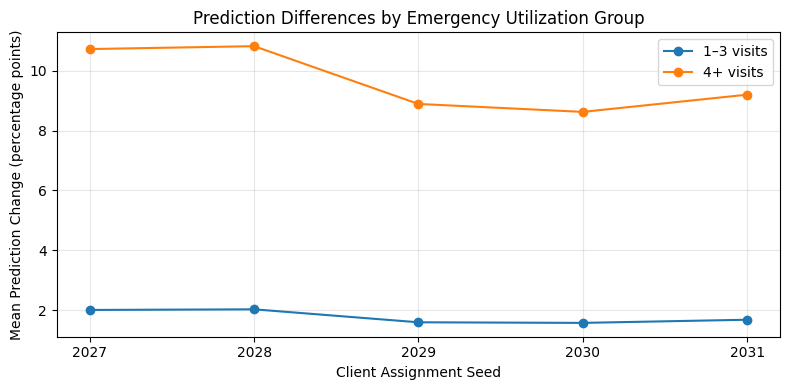

In [39]:
import matplotlib.pyplot as plt

# Keep only the two groups we want to show
plot_data = sensitivity_results[
    sensitivity_results["Emergency group"].isin(["1-3 visits", "4+ visits"])
].copy()

# Create separate tables for plotting
group_1_3 = plot_data[plot_data["Emergency group"] == "1-3 visits"]
group_4_plus = plot_data[plot_data["Emergency group"] == "4+ visits"]

plt.figure(figsize=(8, 4))

plt.plot(
    group_1_3["Seed"],
    group_1_3["Mean change (pp)"],
    marker="o",
    label="1–3 visits"
)

plt.plot(
    group_4_plus["Seed"],
    group_4_plus["Mean change (pp)"],
    marker="o",
    label="4+ visits"
)

plt.xlabel("Client Assignment Seed")
plt.ylabel("Mean Prediction Change (percentage points)")
plt.title("Prediction Differences by Emergency Utilization Group")
plt.xticks(group_1_3["Seed"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


### Phase 3: Summary of Prediction Sensitivity

I repeated the mapping-error experiment using five
different simulated-client assignments.

The prediction differences were consistently larger
for encounters with high emergency utilization.

I will now calculate the mean and variation across
the five experiments to summarize this pattern.


In [40]:

# Summarize prediction changes for each group
group_summary = sensitivity_results.groupby(
    "Emergency group", observed=True, sort=False
)["Mean change (pp)"].agg(
    ["mean", "std", "min", "max"]
)

group_summary.columns = [
    "Average change",
    "Standard deviation",
    "Minimum",
    "Maximum"
]

display(group_summary.round(2))


,Average change,Standard deviation,Minimum,Maximum
Emergency group,,,,
0 visits,0.48,0.08,0.41,0.58
1-3 visits,1.77,0.22,1.57,2.02
4+ visits,9.65,1.04,8.63,10.82



### Phase 3: Final Test Evaluation

The repeated experiments showed small changes in overall
model performance and larger prediction differences
for encounters with high emergency utilization.

I will now evaluate the original E0, E1, and E2 models
using the held-out test dataset.

I will keep the models unchanged to avoid using test
results to influence model development.


In [41]:

# Predict on the untouched test dataset
test_prob_e0 = model_e0.predict_proba(X_test)[:, 1]
test_prob_e1 = model_e1.predict_proba(X_test)[:, 1]
test_prob_e2 = model_e2.predict_proba(X_test)[:, 1]

# Calculate final evaluation metrics
test_results = pd.DataFrame({
    "Model": ["E0", "E1", "E2"],
    "AUROC": [
        roc_auc_score(y_test, p)
        for p in [test_prob_e0, test_prob_e1, test_prob_e2]
    ],
    "AUPRC": [
        average_precision_score(y_test, p)
        for p in [test_prob_e0, test_prob_e1, test_prob_e2]
    ],
    "Brier": [
        brier_score_loss(y_test, p)
        for p in [test_prob_e0, test_prob_e1, test_prob_e2]
    ]
})

display(test_results.round(5))


,Model,AUROC,AUPRC,Brier
0,E0,0.62086,0.19346,0.09607
1,E1,0.62024,0.19065,0.09644
2,E2,0.62086,0.19346,0.09607



### Prediction Sensitivity on the Test Dataset

The final test results showed small differences in
overall performance between E0 and E1.

I will now compare their predicted probabilities
across different emergency-utilization groups.

I want to examine whether encounters with higher
emergency visit counts also show larger prediction
differences in the held-out test dataset.


In [42]:

import numpy as np
import pandas as pd

# Comparing E0 and E1 predictions on the test data
test_review = X_test[["number_emergency"]].copy()

test_review["prediction_change"] = np.abs(
    test_prob_e0 - test_prob_e1
) * 100

# Group encounters by emergency visit count
test_review["emergency_group"] = pd.cut(
    test_review["number_emergency"],
    bins=[-1, 0, 3, np.inf],
    labels=["0 visits", "1-3 visits", "4+ visits"]
)

# lets summarize prediction differences
test_sensitivity = test_review.groupby(
    "emergency_group",
    observed=True
)["prediction_change"].agg(["count", "mean", "median", "max"])

display(test_sensitivity.round(2))

# Verifying that that E2 reproduces E0 predictions
print(
    "E2 predictions match E0:",
    np.allclose(test_prob_e0, test_prob_e2, rtol=0, atol=1e-10)
)


,count,mean,median,max
emergency_group,,,,
0 visits,13593,0.64,0.33,22.78
1-3 visits,1556,2.02,1.57,16.00
4+ visits,170,16.93,12.23,59.12


E2 predictions match E0: True



### Preparing for Patient-Level Bootstrap Analysis

Some patients in the dataset have multiple hospital
encounters.

Before estimating uncertainty, I will examine the
number of unique patients in the test dataset.

This will help me resample patients rather than
individual encounters, preserving the relationship
between repeated encounters from the same patient.


In [43]:

# Getting patient IDs for our held-out test records
test_patients = groups.loc[X_test.index, "patient_nbr"]

# Couning for patients and encounters
patient_counts = test_patients.value_counts()

print("Test encounters:", len(X_test))
print("Unique test patients:", test_patients.nunique())
print("Patients with multiple encounters:",
      (patient_counts > 1).sum())

print("Maximum encounters for one patient:",
      patient_counts.max())


Test encounters: 15319
Unique test patients: 10730
Patients with multiple encounters: 2502
Maximum encounters for one patient: 23



### Phase 3: Final Test Observations

The held-out test results showed small changes in
overall predictive performance between E0 and E1.

However, the prediction differences were not uniform
across encounters.

Encounters with four or more emergency visits showed
an average absolute prediction difference of 16.93
percentage points, compared with 0.64 percentage points
for encounters with zero emergency visits.

This pattern is consistent with the earlier validation
analysis, although the magnitude was different.

The findings suggest that feature-mapping errors may
affect some predictions more strongly than others.

Further uncertainty analysis is needed before making
stronger conclusions about model performance.



### Phase 3: Patient-Level Bootstrap Analysis

I will use bootstrap resampling to estimate uncertainty
in the performance differences between E0 and E1.

Since some patients have multiple hospital encounters,
I will resample patients rather than individual rows.

I will use the same sampled encounters for both models
to make a paired comparison.

The models and their predictions will remain unchanged.


In [44]:

import numpy as np
import pandas as pd

# ConnectING each patient with their test encounter positions
patient_data = pd.DataFrame({
    "patient": test_patients.to_numpy(),
    "row": np.arange(len(test_patients))
})

patient_rows = (
    patient_data.groupby("patient")["row"]
    .apply(list)
    .tolist()
)

print("Patients available for resampling:", len(patient_rows))
print("Test encounters:", len(y_test))


Patients available for resampling: 10730
Test encounters: 15319


In [45]:

from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

rng = np.random.default_rng(2026)
bootstrap_results = []

actual = y_test.to_numpy()

for repeat in range(300):

    # Randomly select patients with replacement
    selected = rng.integers(
        0, len(patient_rows), len(patient_rows)
    )

    # Include every encounter for each selected patient
    rows = np.concatenate([patient_rows[i] for i in selected])

    y_sample = actual[rows]
    e0_sample = test_prob_e0[rows]
    e1_sample = test_prob_e1[rows]

    if len(np.unique(y_sample)) < 2:
        continue

    bootstrap_results.append({
        "AUROC_change": (
            roc_auc_score(y_sample, e1_sample)
            - roc_auc_score(y_sample, e0_sample)
        ),
        "AUPRC_change": (
            average_precision_score(y_sample, e1_sample)
            - average_precision_score(y_sample, e0_sample)
        ),
        "Brier_change": (
            brier_score_loss(y_sample, e1_sample)
            - brier_score_loss(y_sample, e0_sample)
        )
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

print("Bootstrap samples completed:", len(bootstrap_results))
display(bootstrap_results.head().round(5))


Bootstrap samples completed: 300


,AUROC_change,AUPRC_change,Brier_change
0,-0.00031,-0.00333,0.00032
1,-0.00068,-0.00144,0.00066
2,-0.00046,-0.00239,0.00056
3,-0.00207,0.00226,-0.00015
4,-0.00498,-0.00282,0.00062


In [46]:

# SummarizING the bootstrap differences
summary = pd.DataFrame({
    "Average change": bootstrap_results.mean(),
    "Lower 95%": bootstrap_results.quantile(0.025),
    "Upper 95%": bootstrap_results.quantile(0.975)
})

display(summary.round(5))


,Average change,Lower 95%,Upper 95%
AUROC_change,-0.00064,-0.00409,0.00287
AUPRC_change,-0.00249,-0.00935,0.00328
Brier_change,0.00035,-0.00007,0.00082


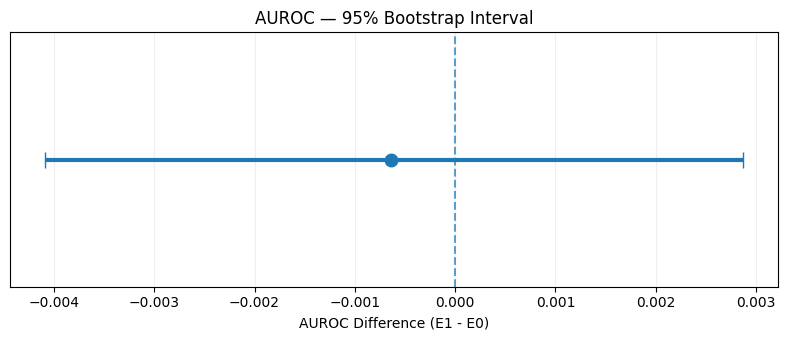

In [47]:

import matplotlib.pyplot as plt
from pathlib import Path


auroc = summary.loc["AUROC_change"]

average = auroc["Average change"]
lower = auroc["Lower 95%"]
upper = auroc["Upper 95%"]

# Calculate the distance from the average to each bound
errors = [
    [average - lower],
    [upper - average]
]

fig, ax = plt.subplots(figsize=(8, 3.5))


ax.errorbar(
    average, 0,
    xerr=errors,
    fmt="o",
    capsize=6,
    markersize=9,
    linewidth=3
)


ax.axvline(0, linestyle="--", alpha=0.7)

ax.set_title("AUROC — 95% Bootstrap Interval")
ax.set_xlabel("AUROC Difference (E1 - E0)")
ax.set_yticks([])
ax.set_ylim(-0.5, 0.5)

ax.grid(axis="x", alpha=0.2)
plt.tight_layout()

# Save for the research report
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/phase3_auroc_bootstrap.png", dpi=300)

plt.show()



### Phase 3: Interpreting Bootstrap Results

I used 300 patient-level bootstrap samples to
estimate uncertainty in the performance differences
between E0 and E1.

The average changes were -0.00064 for AUROC,
-0.00249 for AUPRC, and +0.00035 for Brier score.

All three 95% bootstrap intervals included zero.
Therefore, the small observed performance decreases
do not provide conclusive evidence that E1 performs
worse than E0 at the population level.

However, the experiment also showed larger absolute
prediction changes among encounters with high
emergency utilization.

This suggests that aggregate evaluation metrics may
not fully capture prediction sensitivity to clinical
feature-mapping errors.

These findings are exploratory and limited to one
dataset, a simulated mapping error, and fixed models.



### Saving the Final Experiment Results

I will save the final model comparison, prediction
sensitivity analysis, and bootstrap uncertainty
estimates.

These files will allow me to document the findings
and reproduce the reported results.


In [49]:

from pathlib import Path

# Create the results folder if it does not exist
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save final test performance
test_results.to_csv(
    results_dir / "final_test_results.csv",
    index=False
)

# Save test prediction sensitivity
test_sensitivity.to_csv(
    results_dir / "test_prediction_sensitivity.csv"
)

# Save bootstrap uncertainty intervals
summary.to_csv(
    results_dir / "bootstrap_intervals.csv"
)

# Save repeated experiment results
phase3_comparison.to_csv(
    results_dir / "repeated_experiments.csv",
    index=False
)

print("All Phase 3 results saved successfully.")


All Phase 3 results saved successfully.


In [50]:

# Check the files in the results folder
for file in sorted(results_dir.glob("*.csv")):
    print(file.name)


bootstrap_intervals.csv
final_test_results.csv
phase2b_coefficients.csv
phase2b_model_comparison.csv
repeated_experiments.csv
test_prediction_sensitivity.csv


In [51]:
import os
print(os.getcwd())

/content/clinical-semantic-heterogeneity



### Phase 4: Checking Saved Research Results

I have completed the baseline, mapping-error,
restoration, and robustness experiments.

Before preparing the research report, I will check
that the final results were saved in the project folder.

These files will provide the evidence for my
research findings and documentation.


In [52]:

from pathlib import Path

results_folder = Path("results")

expected_files = [
    "final_test_results.csv",
    "test_prediction_sensitivity.csv",
    "bootstrap_intervals.csv",
    "repeated_experiments.csv"
]

print("Checking saved research results:\n")

for filename in expected_files:
    file = results_folder / filename

    if file.exists():
        print("Saved:", filename)
    else:
        print("Missing:", filename)

print("\nSaved research figures:")

figures_folder = Path("figures")

for file in sorted(figures_folder.glob("*.png")):
    print(file.name)


Checking saved research results:

Saved: final_test_results.csv
Saved: test_prediction_sensitivity.csv
Saved: bootstrap_intervals.csv
Saved: repeated_experiments.csv

Saved research figures:
phase3_auroc_bootstrap.png


In [53]:

from pathlib import Path
from zipfile import ZipFile

project = Path.cwd()
backup = Path("/content/clinical_research_backup.zip")

folders = [
    "src", "scripts", "tests", "configs",
    "docs", "results", "figures", "notebooks",
    "research_note"
]

with ZipFile(backup, "w") as zip_file:
    for folder in folders:
        path = project / folder

        if path.exists():
            for file in path.rglob("*"):
                if file.is_file() and "__pycache__" not in file.parts:
                    zip_file.write(file, file.relative_to(project))

    for file in project.glob("*"):
        if file.is_file() and file.suffix in [".md", ".txt", ".toml"]:
            zip_file.write(file, file.name)

print("Backup created:", backup.name)
print("Backup size:", round(backup.stat().st_size / 1024 / 1024, 2), "MB")


Backup created: clinical_research_backup.zip
Backup size: 0.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>